# Deriva: las reglas del PSI, su valor de referencia y la tasa de falsas alarmas

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (la tasa y el tamaño de cada prueba)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular con el motor el índice de estabilidad poblacional (PSI) de dos muestras agrupadas, leer su banda, su valor p chi-cuadrado y su referencia del 5%, y decir en qué se diferencian;
- enunciar la distribución muestral del PSI sin cambio, $(1/n + 1/m)^{-1}\,\mathrm{PSI} \approx \chi^2_{B-1}$, y usarla para explicar por qué las reglas empíricas de 0,10 y 0,25 tienen tasas de error sin control que dependen de los tamaños de muestra;
- medir la tasa de falsas alarmas de las dos reglas y la potencia de la referencia, del chi-cuadrado y de Kolmogórov-Smirnov a lo largo de una escalera de desplazamientos de la media, y repetir una fila versionada desde su semilla;
- recalcular las celdas de la Tabla 4 de Yurdakul y Naranjo frente a la reproducción versionada (50 de 54) y leer las cuatro que difieren;
- decir por qué una población que deriva no vuelve descalibrado a un modelo correcto, y qué significa eso para la alarma que debe levantar un validador.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `drift` del caso C22 (validar al validador). Su panel `stability` sortea dos muestras de una variable siguiendo el diseño de Yurdakul y Naranjo (2020): una muestra base de $N(0, 8^2)$, agrupada en sus diez deciles poblacionales, y una muestra objetivo de $N(\mu, 8^2)$ con $\mu$ una fracción de desviación estándar en la escalera 0; 0,05; 0,1; 0,2; 0,3 y 0,5. Su panel `calibration` sortea una cartera logística cuyas covariables se desplazan en la misma medida mientras el modelo sigue exactamente correcto. Cada conjunto viene de un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`); las tasas publicadas se citan del artículo (solo derivadas, como números).

- **Archivo que se lee:** `data/derived/C22/drift.json`: `outputs.simulations` (30 filas, 2.000 repeticiones cada una, muestras de 1.000), `outputs.golden` (las 54 celdas de la Tabla 4 de Yurdakul y Naranjo con la tasa publicada y la medida), `outputs.generators` e `impact`. Las muestras de 100 de la familia están en la familia `null` (`stability.psi@n100`), que el cuaderno 02 lee de `data/derived/C22/null.json` y que aquí se repite desde su semilla.
- **Reglas:** las filas de `stability.psi` llevan cuatro reglas de decisión: `p<0.05` y `p<0.01` (la referencia chi-cuadrado) y las dos reglas empíricas, `metric>0.1` y `metric>0.25`.

La celda siguiente carga el artefacto e imprime la escalera, los paneles y las etiquetas de las reglas.

In [2]:
# Cargar la familia de deriva, indexar sus filas e imprimir la escalera, los paneles y las reglas de decisión de las filas del PSI
LANG = "es"
ROOT = Path("../../..").resolve()
drift = json.loads((ROOT / "data" / "derived" / "C22" / "drift.json").read_text(encoding="utf-8"))
out = drift["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]

print("calculado por riskvalidation", drift["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)
print("escalera:", out["ladder"]["label"][LANG], ladder)
measure_name = {"size": "tamaño", "power": "potencia"}
for panel in out["panels"]:
    print(f"{panel['label'][LANG]:30s} {sum(1 for r in rows.values() if r['panel'] == panel['id'])} filas | mide: {measure_name[panel['measures']]}")
print("reglas de decisión de una fila del PSI:", list(rows["stability.psi@s0.1"]["rates"]))

calculado por riskvalidation 0.4.3 | instalado 0.8.1
escalera: desplazamiento de la media (desviaciones estándar) [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
Estabilidad                    18 filas | mide: potencia
Calibración                    12 filas | mide: tamaño
reglas de decisión de una fila del PSI: ['p<0.05', 'p<0.01', 'metric>0.1', 'metric>0.25']


## Método

**El PSI.** Con $B$ intervalos fijos, proporciones de desarrollo $e_i$ y proporciones actuales $a_i$, el índice es

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

la divergencia de Kullback-Leibler simetrizada. La práctica lo lee frente a dos reglas empíricas, 0,10 (poco cambio por debajo) y 0,25 (cambio significativo por encima), «usadas sin referencia a tasas de error de tipo I o de tipo II» (Yurdakul y Naranjo, 2020).

**Su distribución muestral.** Para muestras base y objetivo de $n$ y $m$ observaciones sobre intervalos fijos, el Teorema 3.3 del artículo da, sin cambio,

$$\Big(\tfrac1n + \tfrac1m\Big)^{-1}\,\mathrm{PSI} \;\approx\; \chi^2_{B-1}, \qquad E[\mathrm{PSI}] \approx \Big(\tfrac1n + \tfrac1m\Big)(B-1)$$

de modo que el PSI lleva un ruido muestral que depende solo de los tamaños de muestra, y la prueba que controla el error de tipo I rechaza cuando $\mathrm{PSI} > (1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$. La función `psi_benchmark` del motor devuelve ese valor crítico y `stability_psi` informa el valor p correspondiente. Una banda fija no puede seguirlo.

Los pasos calculan el piso de ruido, la referencia y un primer resultado, miden las falsas alarmas de las reglas, la potencia a lo largo de la escalera, reproducen la Tabla 4 del artículo, y separan la deriva de la descalibración.

### Paso 1: el piso de ruido del PSI

La primera línea de la celda es el PSI esperado cuando nada cambia, $(1/n + 1/m)(B-1)$ con $B = 10$, para cuatro tamaños de muestra iguales, junto a la referencia del 5% de `psi_benchmark`. Con 100 observaciones por muestra, el PSI esperado sin cambio ya supera la regla empírica de 0,10. La segunda parte calcula el PSI poblacional de los desplazamientos de la escalera (sin muestreo: el PSI de las probabilidades por decil de las dos poblaciones que lleva la `truth` del generador, mediante `population_psi`) y lo compara con el piso de ruido de muestras de 1.000.

In [3]:
# PSI esperado sin cambio y referencia del 5% para cuatro tamaños de muestra, y luego el PSI poblacional de cada desplazamiento de la escalera
from riskvalidation.generators import TwoSample, population_psi
from riskvalidation.validation.stability import psi_benchmark

for size in (100, 200, 400, 1000):
    expected_null = (1 / size + 1 / size) * (10 - 1)
    print(f"n = m = {size:4d} | PSI esperado sin cambio {expected_null:.4f} | referencia del 5% {psi_benchmark(size, size):.4f}")

print("PSI poblacional de cada desplazamiento (sin muestreo):")
for shift in ladder:
    truth = TwoSample(1000, 1000, shift=shift).truth()
    psi_population = population_psi(truth["bins_base"], truth["bins_target"])
    print(f"  desplazamiento {shift:4.2f} | PSI poblacional {psi_population:.4f} | guardado en la verdad {truth['population_psi']:.4f}")

n = m =  100 | PSI esperado sin cambio 0.1800 | referencia del 5% 0.3384
n = m =  200 | PSI esperado sin cambio 0.0900 | referencia del 5% 0.1692
n = m =  400 | PSI esperado sin cambio 0.0450 | referencia del 5% 0.0846
n = m = 1000 | PSI esperado sin cambio 0.0180 | referencia del 5% 0.0338
PSI poblacional de cada desplazamiento (sin muestreo):
  desplazamiento 0.00 | PSI poblacional 0.0000 | guardado en la verdad 0.0000
  desplazamiento 0.05 | PSI poblacional 0.0024 | guardado en la verdad 0.0024
  desplazamiento 0.10 | PSI poblacional 0.0096 | guardado en la verdad 0.0096
  desplazamiento 0.20 | PSI poblacional 0.0383 | guardado en la verdad 0.0383
  desplazamiento 0.30 | PSI poblacional 0.0861 | guardado en la verdad 0.0861
  desplazamiento 0.50 | PSI poblacional 0.2377 | guardado en la verdad 0.2377


### Paso 2: dónde quedan las reglas empíricas frente a la referencia

La referencia del 5% iguala a una banda fija cuando $(2/n)\,\chi^2_{0,95;\,9}$ es igual a la banda, lo que da el tamaño de muestra en que la regla y la referencia coinciden: por debajo, la regla rechaza más de 5% de las veces cuando nada cambia, por encima rechaza menos. La celda siguiente lo despeja con el cuantil chi-cuadrado de SciPy, e imprime la referencia para los seis pares de tamaños de muestra de la Tabla 4 de Yurdakul y Naranjo.

In [4]:
# Tamaño de muestra en que cada regla empírica iguala la referencia del 5%, y la referencia de los seis pares de la Tabla 4
critical = stats.chi2.ppf(0.95, 9)
for band in (0.10, 0.25):
    print(f"regla empírica {band:.2f} | iguala la referencia del 5% con n = m = {2 * critical / band:.0f}")
for m, n in ((100, 100), (100, 200), (100, 400), (200, 200), (200, 400), (400, 400)):
    print(f"m = {m:3d}, n = {n:3d} | referencia {psi_benchmark(n, m):.4f}")

regla empírica 0.10 | iguala la referencia del 5% con n = m = 338
regla empírica 0.25 | iguala la referencia del 5% con n = m = 135
m = 100, n = 100 | referencia 0.3384
m = 100, n = 200 | referencia 0.2538
m = 100, n = 400 | referencia 0.2115
m = 200, n = 200 | referencia 0.1692
m = 200, n = 400 | referencia 0.1269
m = 400, n = 400 | referencia 0.0846


### Paso 3: tres conjuntos, tres lecturas

`stability_psi` recibe los conteos por intervalo de las dos muestras y devuelve un `TestResult` con el PSI como métrica, el valor p chi-cuadrado, la banda convencional en sus notas, y la referencia del 5% en `extras`. La celda siguiente sortea tres conjuntos desde los generadores e imprime lo que dice el motor: muestras de 100 sin cambio, muestras de 1.000 sin cambio, y muestras de 1.000 con un desplazamiento de 0,2 desviaciones estándar. La banda y el valor p no tienen por qué coincidir, y ese es el punto.

In [5]:
# Sortear tres conjuntos y leer el PSI, su banda convencional, su referencia y su valor p en cada uno
from riskvalidation.validation import stability_psi

cases = (("100 vs 100, sin cambio", TwoSample(100, 100)), ("1000 vs 1000, sin cambio", TwoSample(1000, 1000)),
         ("1000 vs 1000, desplazamiento 0.2 DE", TwoSample(1000, 1000, shift=0.2)))
for label, generator in cases:
    sample = generator.draw(np.random.default_rng(31))
    result = stability_psi(sample["expected_counts"], sample["actual_counts"])
    print(f"{label:38s} PSI {result.metric:.4f} | banda: {result.extras['band']:20s} | referencia 5% {result.extras['benchmark_05']:.4f} | valor p {result.p_value:.4f}")

100 vs 100, sin cambio                 PSI 0.2796 | banda: significant change   | referencia 5% 0.3384 | valor p 0.1231
1000 vs 1000, sin cambio               PSI 0.0146 | banda: little change        | referencia 5% 0.0338 | valor p 0.6047
1000 vs 1000, desplazamiento 0.2 DE    PSI 0.0392 | banda: little change        | referencia 5% 0.0338 | valor p 0.0205


### Paso 4: las falsas alarmas de las dos reglas, repetidas

La familia `null` midió las reglas sobre dos muestras de 100 sin ningún cambio. La celda siguiente repite esa fila desde su semilla versionada, con las dos reglas agregadas exactamente como las agregó el artefacto, y compara los conteos. Luego corre el mismo experimento para cuatro tamaños de muestra con una semilla nueva y 4.000 repeticiones cada uno, para ver cómo se mueve con el tamaño de las muestras la tasa de error de cada regla: esa es la tasa de error que, según el artículo, nadie había declarado.

In [6]:
# Repetir la fila versionada con n = 100 y sus reglas, y luego medir la tasa de falsas alarmas de ambas reglas con cuatro tamaños de muestra
from riskvalidation.harness import metric_above, simulate

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
committed = next(r for r in null["outputs"]["simulations"] if r["key"] == "stability.psi@n100")
replay = simulate("stability.psi", TwoSample(100, 100), n_rep=committed["n_rep"], seed=committed["seed"], rules=rules)
for rule in ("p<0.05", "metric>0.1", "metric>0.25"):
    print(f"{rule:12s} | repetición {replay.rates[rule].rejections} | versionado {committed['rates'][rule]['rejections']}")

print("tasa de falsas alarmas cuando nada cambió (semilla nueva, 4000 repeticiones, ± EE de Monte Carlo):")
for size in (100, 200, 400, 1000):
    sim = simulate("stability.psi", TwoSample(size, size), n_rep=4000, seed=2026, rules=rules)
    shown = {name: f"{sim.rates[rule].rate:.3f} ± {sim.rates[rule].se:.3f}" for name, rule in (("a", "metric>0.1"), ("b", "metric>0.25"), ("c", "p<0.05"))}
    print(f"  n = m = {size:4d} | PSI > 0.10: {shown['a']} | PSI > 0.25: {shown['b']} | referencia chi-cuadrado al 5%: {shown['c']}")

p<0.05       | repetición 279 | versionado 279
metric>0.1   | repetición 3399 | versionado 3399
metric>0.25  | repetición 914 | versionado 914
tasa de falsas alarmas cuando nada cambió (semilla nueva, 4000 repeticiones, ± EE de Monte Carlo):
  n = m =  100 | PSI > 0.10: 0.857 ± 0.006 | PSI > 0.25: 0.227 ± 0.007 | referencia chi-cuadrado al 5%: 0.075 ± 0.004
  n = m =  200 | PSI > 0.10: 0.379 ± 0.008 | PSI > 0.25: 0.004 ± 0.001 | referencia chi-cuadrado al 5%: 0.061 ± 0.004
  n = m =  400 | PSI > 0.10: 0.021 ± 0.002 | PSI > 0.25: 0.000 ± 0.000 | referencia chi-cuadrado al 5%: 0.052 ± 0.004
  n = m = 1000 | PSI > 0.10: 0.000 ± 0.000 | PSI > 0.25: 0.000 ± 0.000 | referencia chi-cuadrado al 5%: 0.049 ± 0.003


### Paso 5: la potencia a lo largo de la escalera

El panel `stability` midió, para muestras de 1.000, con qué frecuencia dispara cada regla cuando se mueve la media del objetivo: las dos reglas empíricas, la referencia chi-cuadrado (`p<0.05` del PSI), la prueba chi-cuadrado de homogeneidad y la prueba de Kolmogórov-Smirnov. La celda siguiente imprime la tabla, con el PSI poblacional del paso 1 en la primera columna para mostrar cuán poco índice lleva cada desplazamiento, y dibuja las curvas con intervalos de Wilson.

desplaz. PSI poblacional      PSI > 0.10      PSI > 0.25  PSI referencia  chi-cuadrado d  Kolmogorov-Smi
   0.00          0.0000           0.000           0.000           0.050           0.046           0.055
   0.05          0.0024           0.000           0.000           0.096           0.093           0.149
   0.10          0.0096           0.000           0.000           0.272           0.263           0.465
   0.20          0.0383           0.028           0.000           0.896           0.885           0.973
   0.30          0.0861           0.531           0.000           1.000           1.000           1.000
   0.50          0.2377           1.000           0.556           1.000           1.000           1.000


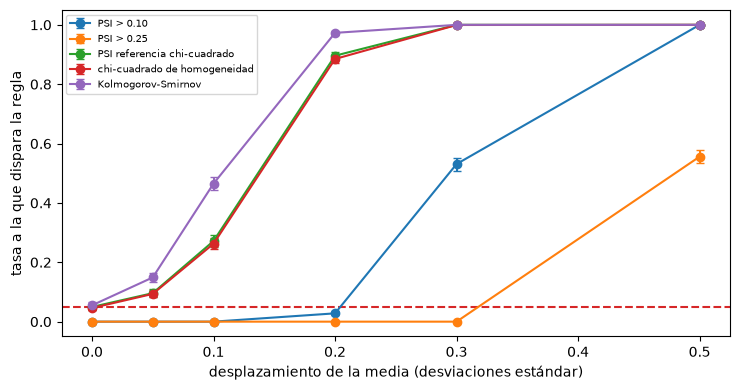

In [7]:
# Imprimir la tasa de disparo de cada regla y prueba a lo largo de la escalera (muestras de 1000) y dibujar las curvas con intervalos de Wilson
curves = {
    "PSI > 0.10": ("stability.psi", "metric>0.1"), "PSI > 0.25": ("stability.psi", "metric>0.25"),
    "PSI referencia chi-cuadrado": ("stability.psi", "p<0.05"),
    "chi-cuadrado de homogeneidad": ("stability.chi2", "p<0.05"), "Kolmogorov-Smirnov": ("stability.ks", "p<0.05"),
}
print(f"{'desplaz.':>7s} {'PSI poblacional':>15s} " + " ".join(f"{name[:14]:>15s}" for name in curves))
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, (test, rule) in curves.items():
    cells = [rows[f"{test}@s{s:g}"]["rates"][rule] for s in ladder]
    rate = np.array([c["rate"] for c in cells])
    low = np.array([c["wilson_low"] for c in cells])
    high = np.array([c["wilson_high"] for c in cells])
    ax.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, label=name)
for s in ladder:
    psi_pop = TwoSample(1000, 1000, shift=s).truth()["population_psi"]
    print(f"{s:7.2f} {psi_pop:15.4f} " + " ".join(f"{rows[f'{t}@s{s:g}']['rates'][r]['rate']:15.3f}" for t, r in curves.values()))
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel(out["ladder"]["label"][LANG])
ax.set_ylabel("tasa a la que dispara la regla")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Paso 6: la Tabla 4 de Yurdakul y Naranjo, celda por celda

La Tabla 4 del artículo da la tasa a la que disparan las dos reglas empíricas y la referencia chi-cuadrado para seis pares de tamaños de muestra y tres desplazamientos (0, un cuarto y media desviación estándar), con 10.000 corridas. El artefacto guarda las 54 celdas con la tasa publicada y la medida. La celda siguiente recalcula cada diferencia estandarizada con `agrees_with_published` del motor, cuenta las concordancias, e imprime las celdas que discrepan y la diferencia promedio sobre las celdas estrictamente entre 0 y 1.

In [8]:
# Recalcular la diferencia estandarizada de cada celda de la Tabla 4, contar las concordancias y listar las fallas
from functools import reduce

from riskvalidation.harness import Rate, agrees_with_published

GLOSSARY = (("Table", "Tabla"), ("traffic", "semáforo"), ("shift", "desplazamiento"), (" SD", " DE"), ("chi-square", "chi-cuadrado"), ("section", "sección"), ("nested", "anidados"))
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)

n_runs = golden["runs"]
agree, inside, misses = 0, [], []
for cell in golden["cells"]:
    ok, z = agrees_with_published(Rate(round(cell["measured"] * n_runs), n_runs), cell["published"], golden["runs_published"])
    agree += ok
    if 0 < cell["published"] < 1:
        inside.append(z)
    if not ok:
        misses.append((cell, z))
print("celdas que concuerdan:", agree, "de", len(golden["cells"]), "|", "versionado:", golden["agree"], "|", "z medio, celdas estrictamente entre 0 y 1:", round(float(np.mean(inside)), 3))
for cell, z in misses:
    print(f"  {gloss(cell['row']):13s} {gloss(cell['column']):28s} publicada {cell['published']:.3f} | medida {cell['measured']:.4f} | z {z:+.2f}")
print("toda falla está medida sobre lo impreso:", ("sí" if all(c["measured"] > c["published"] for c, _ in misses) else "no"))

celdas que concuerdan: 50 de 54 | versionado: 50 | z medio, celdas estrictamente entre 0 y 1: 0.649
  m 100, n 400  desplazamiento 0.25 DE, PSI > 0.10 publicada 0.834 | medida 0.8522 | z +3.54
  m 100, n 400  desplazamiento 0.5 DE, PSI > 0.25 publicada 0.787 | medida 0.8098 | z +4.02
  m 200, n 200  desplazamiento 0 DE, chi-cuadrado publicada 0.057 | medida 0.0688 | z +3.44
  m 200, n 400  desplazamiento 0.5 DE, PSI > 0.25 publicada 0.720 | medida 0.7421 | z +3.52
toda falla está medida sobre lo impreso: sí


La celda siguiente imprime el primer grupo de columnas de la tabla, las celdas sin desplazamiento, donde el artículo dice que el error de tipo I de la regla de 0,10 es demasiado grande salvo que ambas muestras superen 400, y donde la referencia chi-cuadrado se mantiene cerca de su nivel.

In [9]:
# Imprimir las tasas publicadas y medidas de la Tabla 4 para las celdas sin desplazamiento
print(f"{'muestras':14s} {'PSI > 0.10':>20s} {'PSI > 0.25':>20s} {'referencia chi-cuadrado':>24s}   (publicada / medida)")
for row_name in ("m 100, n 100", "m 100, n 200", "m 100, n 400", "m 200, n 200", "m 200, n 400", "m 400, n 400"):
    cells = {c["column"]: c for c in golden["cells"] if c["row"] == row_name}
    parts = []
    for column in ("shift 0 SD, PSI > 0.10", "shift 0 SD, PSI > 0.25", "shift 0 SD, chi-square"):
        c = cells[column]
        parts.append(f"{c['published']:.3f} / {c['measured']:.4f}")
    print(f"{row_name:14s} {parts[0]:>20s} {parts[1]:>20s} {parts[2]:>24s}")

muestras                 PSI > 0.10           PSI > 0.25  referencia chi-cuadrado   (publicada / medida)
m 100, n 100         0.849 / 0.8525       0.233 / 0.2284           0.076 / 0.0753
m 100, n 200         0.691 / 0.6959       0.074 / 0.0733           0.069 / 0.0669
m 100, n 400         0.560 / 0.5668       0.029 / 0.0296           0.066 / 0.0678
m 200, n 200         0.369 / 0.3807       0.004 / 0.0043           0.057 / 0.0688
m 200, n 400         0.160 / 0.1599       0.000 / 0.0005           0.060 / 0.0575
m 400, n 400         0.020 / 0.0186       0.000 / 0.0000           0.051 / 0.0555


### Paso 7: la deriva no es descalibración

El panel `calibration` desplaza las covariables de una cartera logística en las mismas medidas mientras el modelo conserva sus coeficientes verdaderos, de modo que sus PD siguen correctas para cada deudor. Una alarma de deriva y una prueba de calibración responden entonces preguntas distintas: la población se movió, y el modelo sigue siendo correcto. La celda siguiente imprime la tasa a la que rechazan Hosmer-Lemeshow y Spiegelhalter a lo largo de la escalera, con el hallazgo del artefacto sobre ello.

In [10]:
# Imprimir la tasa de rechazo de Hosmer-Lemeshow y Spiegelhalter bajo un desplazamiento de covariables con un modelo correcto
print(f"{'desplaz.':>7s} {'Hosmer-Lemeshow':>17s} {'Spiegelhalter':>15s}")
for s in ladder:
    hl = rows[f"pd.hosmer_lemeshow@s{s:g}"]["rates"]["p<0.05"]["rate"]
    sp = rows[f"pd.spiegelhalter@s{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:7.2f} {hl:17.4f} {sp:15.4f}")
finding = next(f for f in drift["findings"] if f["id"] == "F-DRIFT-NOT-MISCAL")
status_name = {"accepted": "aceptado", "closed": "cerrado", "open": "abierto"}
print(finding["id"], finding["severity"], status_name[finding["status"]], "|", finding["title"][LANG])

desplaz.   Hosmer-Lemeshow   Spiegelhalter
   0.00            0.0510          0.0540
   0.05            0.0560          0.0560
   0.10            0.0580          0.0540
   0.20            0.0585          0.0525
   0.30            0.0530          0.0560
   0.50            0.0485          0.0500
F-DRIFT-NOT-MISCAL S4 aceptado | La deriva no es descalibración: un modelo correcto sigue calibrado ante un desplazamiento de covariables; las alarmas de estabilidad y las pruebas de calibración responden preguntas distintas


## Resultados

- **El PSI tiene un piso de ruido que depende solo de los tamaños de muestra.** Con diez intervalos, el PSI esperado cuando nada cambia es 0,180 para dos muestras de 100, 0,090 para 200, 0,045 para 400 y 0,018 para 1.000. La referencia del 5% es 0,338, 0,169, 0,085 y 0,034. Una banda fija de 0,10 queda bajo el piso de ruido con 100 observaciones, cerca de él con 200 y muy sobre él con 1.000, así que no puede significar lo mismo con dos tamaños de muestra. Las dos reglas igualan la referencia del 5% con 338 y con 135 observaciones por muestra.
- **La banda y la prueba pueden discrepar en ambos sentidos.** Dos muestras de 100 sin cambio dieron un PSI de 0,280, «cambio significativo» según la banda, con un valor p de 0,12 y una referencia de 0,338. Dos muestras de 1.000 desplazadas 0,2 desviaciones estándar dieron un PSI de 0,039, «poco cambio» según la banda, sobre la referencia de 0,034 con un valor p de 0,021. Un conjunto de cada uno es una ilustración, no una tasa; las tasas siguen.
- **La tasa de falsas alarmas de la regla de 0,10 es 85,7% con muestras de 100.** Es 37,9% con 200 y 2,1% con 400, y 0% con 1.000. La regla de 0,25 dispara 22,7% de las veces con 100 observaciones y casi nunca sobre 200. La repetición de la fila versionada da exactamente sus conteos (279, 3.399 y 914). La referencia chi-cuadrado se mantiene entre 4,9% y 7,5%, más cerca de 5% a medida que crecen las muestras, con un leve exceso en muestras pequeñas que también muestra la Tabla 4 de Yurdakul y Naranjo.
- **Las bandas fijas pierden potencia al crecer las muestras.** Con 1.000 por muestra y un desplazamiento de 0,1 desviaciones estándar la referencia dispara 27,2% de las veces, el chi-cuadrado de homogeneidad 26,3%, Kolmogórov-Smirnov 46,5% y las dos reglas empíricas nunca. Con 0,2 la referencia dispara 89,6% y Kolmogórov-Smirnov 97,3%, mientras la regla de 0,10 dispara 2,8% y la de 0,25 nunca. La regla de 0,25 necesita un desplazamiento de 0,5 y entonces dispara 55,6% de las veces. El PSI poblacional lo explica: 0,0096 con 0,1, 0,0383 con 0,2, 0,2377 con 0,5, muy bajo las bandas de 0,10 y 0,25 para los desplazamientos que una referencia sí ve.
- **La Tabla 4 se reproduce en 50 de 54 celdas, con un desfase declarado.** Las cuatro celdas que difieren están todas medidas sobre lo impreso, con diferencias estandarizadas de 3,44 a 4,02; la media sobre las celdas estrictamente entre 0 y 1 es +0,649. La nota del artefacto dice que ningún tratamiento de los intervalos vacíos explica el desfase porque el artículo no declara el suyo, y que cada hallazgo cualitativo del artículo se reproduce, como muestran las columnas sin desplazamiento: la regla de 0,10 queda muy sobre su nivel con muestras pequeñas, la de 0,25 colapsa sobre 200 y la referencia se mantiene cerca de 5%.
- **La deriva no es descalibración.** Con cada covariable desplazada hasta media desviación estándar y el modelo exactamente correcto, Hosmer-Lemeshow rechaza entre 4,85% y 5,85% y Spiegelhalter entre 5,0% y 5,6%, en su nivel en todo momento. Una alarma de estabilidad dice que la población se movió; si las PD siguen siendo correctas es una pregunta para las pruebas de calibración, y un validador debe levantar las dos alarmas por separado.

Lo que este cuaderno no muestra: el PSI con intervalos tomados de los cuantiles de la propia muestra de desarrollo, la deriva de una variable que no es normal, ni la elección de diez intervalos; cada cosa cambia las constantes pero no el argumento. Los desplazamientos son una elección de diseño de Contraste, y la potencia frente a ellos no es una probabilidad de detectar deriva en una cartera real.

## Resumen

- El PSI tiene un piso de ruido de $(1/n + 1/m)(B-1)$ que depende solo de los tamaños de muestra, y una referencia del 5% $(1/n + 1/m)\chi^2_{0,95;\,B-1}$ que lo sigue; una banda fija no puede.
- La regla de 0,10 dispara en 85,7% de las muestras de 100 cuando nada cambió, y la de 0,25 en 22,7%; con 1.000 por muestra ambas casi callan ante desplazamientos que la referencia detecta entre 27% y 90% de las veces.
- Kolmogórov-Smirnov fue la prueba de deriva más potente medida aquí, y el chi-cuadrado de homogeneidad iguala a la referencia del PSI.
- La Tabla 4 de Yurdakul y Naranjo se reproduce en 50 de 54 celdas, las cuatro fallas todas sobre lo impreso, con un desfase declarado de 0,65 errores estándar en promedio.
- La deriva no es descalibración: un modelo correcto queda en su tamaño ante un desplazamiento de covariables, de modo que las dos alarmas responden preguntas distintas.

**Qué probar a continuación.** Repite la fila n = 100 con la opción `binning="sample"` de `TwoSample` (intervalos tomados de los cuantiles de la propia muestra de desarrollo) y compara su tasa de falsas alarmas con la de intervalos fijos; luego lee el cuaderno 06.

## Referencias

- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4): las reglas empíricas, el Teorema 3.3, la referencia y la Tabla 4. https://doi.org/10.21314/JRMV.2020.227
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.